# Machine Learning-Based Cardiometabolic Risk Stratification Using Population Health Data: An Explainable Clinical Decision Support System

## Notebook 3: Feature Engineering and Model Development

**Student Name:** Vanshika Karnwal | Student ID: 201957572  
**Supervisor:** Dr Baoru Huang  
**Module:** COMP702 Dissertation | University of Liverpool  
**Dataset:** NHANES 2017-March 2020 Pre-Pandemic  
**Source:** https://wwwn.cdc.gov/nchs/nhanes/Default.aspx

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

print("Libraries loaded")

Libraries loaded


In [2]:
df = pd.read_csv(r'C:\Users\VANSHIKA KARNWAL\OneDrive\Desktop\DISSERTATION\DATASETS\nhanes_final_dataset_dissertation.csv')
print("Shape:", df.shape)
print("Risk Distribution:", df['Risk_category'].value_counts().to_dict())

Shape: (3528, 22)
Risk Distribution: {'High': 1470, 'Moderate': 1391, 'Low': 667}


## 1. Feature Engineering

### 1.1 Feature and Target Separation
Variables used to define the risk label (HbA1c, Fasting_Glucose, 
Systolic_BP, BMI) are excluded from the feature set to prevent 
data leakage. SEQN, Creatinine (replaced by eGFR), and eGFR_Stage 
(categorical duplicate of eGFR) are also removed.

In [3]:
# Remove leakage variables and non-features
X = df.drop(columns=['Risk_category', 'SEQN', 
                      'HbA1c', 'Fasting_Glucose', 
                      'Systolic_BP', 'BMI',
                      'Creatinine', 'eGFR_Stage'],
            errors='ignore')

y = df['Risk_category']

print("Features:", X.columns.tolist())
print("Feature count:", X.shape[1])
print("Target distribution:", y.value_counts().to_dict())

Features: ['Age', 'Gender', 'Race', 'Diastolic_BP', 'Waist_Circumference', 'Total_Cholesterol', 'HDL_Cholesterol', 'Triglycerides', 'LDL_Cholesterol', 'Smoking_Status', 'Total_PA_Minutes', 'Sedentary_Hours', 'Uric_Acid', 'GGT', 'eGFR']
Feature count: 15
Target distribution: {'High': 1470, 'Moderate': 1391, 'Low': 667}


### 1.2 Categorical Encoding

- **Gender:** Label encoded (Male=0, Female=1)
- **Smoking_Status:** Ordinal encoded (Never=0, Former=1, Current=2)
- **Race:** One-hot encoded with drop_first=True to avoid multicollinearity
- **Target:** Label encoded (High=0, Low=1, Moderate=2)

In [4]:
# Encode Gender
X['Gender'] = X['Gender'].map({'Male': 0, 'Female': 1})

# Encode Smoking Status (ordinal — meaningful order)
X['Smoking_Status'] = X['Smoking_Status'].map({'Never': 0, 'Former': 1, 'Current': 2})

# One-hot encode Race
X = pd.get_dummies(X, columns=['Race'], drop_first=True)

# Encode target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Classes:", le.classes_)
print("Encoding: High=0, Low=1, Moderate=2")
print("X shape after encoding:", X.shape)
print("Columns:", X.columns.tolist())

Classes: ['High' 'Low' 'Moderate']
Encoding: High=0, Low=1, Moderate=2
X shape after encoding: (3528, 19)
Columns: ['Age', 'Gender', 'Diastolic_BP', 'Waist_Circumference', 'Total_Cholesterol', 'HDL_Cholesterol', 'Triglycerides', 'LDL_Cholesterol', 'Smoking_Status', 'Total_PA_Minutes', 'Sedentary_Hours', 'Uric_Acid', 'GGT', 'eGFR', 'Race_Non-Hispanic Asian', 'Race_Non-Hispanic Black', 'Race_Non-Hispanic White', 'Race_Other Hispanic', 'Race_Other/Multi-Racial']


### 1.3 Train-Test Split, Scaling and SMOTE

- **80/20 stratified split** - preserves class proportions in both sets
- **StandardScaler** - fitted on training set only, applied to both
- **SMOTE** - applied to training set only after splitting to prevent data leakage

In [5]:
# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

# StandardScaler — fit on training only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nScaling applied")

# SMOTE — training set only
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("\nBefore SMOTE:", np.unique(y_train, return_counts=True)[1])
print("After SMOTE: ", np.unique(y_train_smote, return_counts=True)[1])

Training set: (2822, 19)
Test set: (706, 19)

Scaling applied

Before SMOTE: [1176  533 1113]
After SMOTE:  [1176 1176 1176]


## 2. Model Development

Four classification algorithms are trained and compared:
1. **Logistic Regression** - linear baseline model
2. **Decision Tree** - interpretable non-linear model (max_depth=10)
3. **Random Forest** - ensemble of 100 decision trees
4. **XGBoost** - gradient boosting algorithm

In [6]:
# Define all models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=10),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='mlogloss')
}

results = {}

for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    y_pred = model.predict(X_test_scaled)
    results[name] = y_pred
    print(f"\n{'='*50}")
    print(f"{name}")
    print('='*50)
    print(classification_report(y_test, y_pred,
          target_names=['High', 'Low', 'Moderate']))


Logistic Regression
              precision    recall  f1-score   support

        High       0.73      0.72      0.72       294
         Low       0.57      0.74      0.64       134
    Moderate       0.58      0.50      0.54       278

    accuracy                           0.64       706
   macro avg       0.62      0.65      0.63       706
weighted avg       0.64      0.64      0.63       706


Decision Tree
              precision    recall  f1-score   support

        High       0.74      0.66      0.70       294
         Low       0.50      0.65      0.57       134
    Moderate       0.53      0.52      0.53       278

    accuracy                           0.60       706
   macro avg       0.59      0.61      0.60       706
weighted avg       0.61      0.60      0.60       706


Random Forest
              precision    recall  f1-score   support

        High       0.75      0.73      0.74       294
         Low       0.61      0.63      0.62       134
    Moderate       0.58 

## 3. Model Comparison

In [7]:
summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost'],
    'Accuracy': [0.64, 0.60, 0.65, 0.66],
    'High F1':  [0.72, 0.70, 0.74, 0.74],
    'Low F1':   [0.64, 0.57, 0.62, 0.62],
    'Moderate F1': [0.54, 0.53, 0.58, 0.61],
    'Macro F1': [0.63, 0.60, 0.65, 0.66]
})

print("Model Performance Summary:")
print(summary.to_string(index=False))

Model Performance Summary:
              Model  Accuracy  High F1  Low F1  Moderate F1  Macro F1
Logistic Regression      0.64     0.72    0.64         0.54      0.63
      Decision Tree      0.60     0.70    0.57         0.53      0.60
      Random Forest      0.65     0.74    0.62         0.58      0.65
            XGBoost      0.66     0.74    0.62         0.61      0.66


## 4. Confusion Matrices

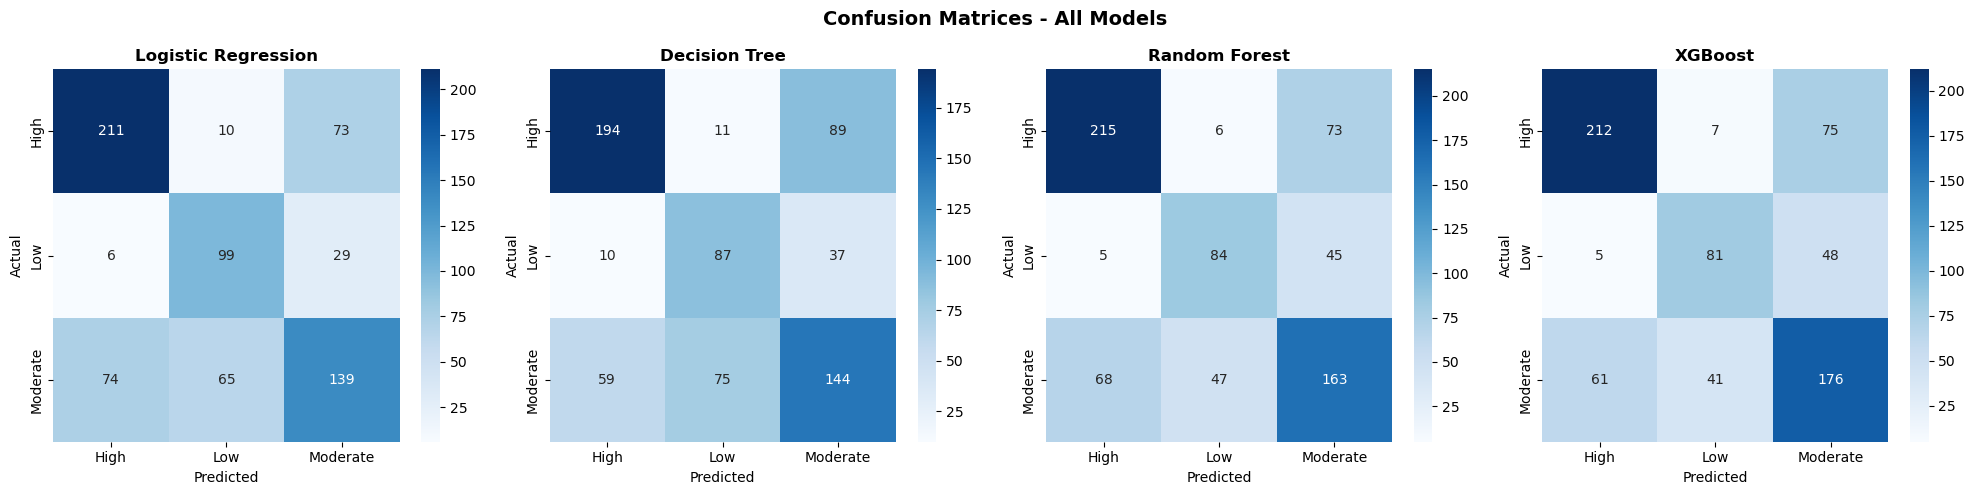

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, (name, y_pred) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['High','Low','Moderate'],
                yticklabels=['High','Low','Moderate'],
                ax=ax)
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.suptitle('Confusion Matrices - All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

## 5. Hyperparameter Tuning (XGBoost)

GridSearchCV with 5-fold cross-validation is applied to XGBoost
to identify optimal hyperparameters.

In [12]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

xgb_base = XGBClassifier(random_state=42, eval_metric='mlogloss')

grid_search = GridSearchCV(xgb_base, param_grid, cv=5,
                           scoring='f1_macro', n_jobs=-1, verbose=1)
grid_search.fit(X_train_smote, y_train_smote)

print("\nBest parameters:", grid_search.best_params_)
print(f"Best CV F1 score: {grid_search.best_score_:.3f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits

Best parameters: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Best CV F1 score: 0.740


In [10]:
xgb_tuned = XGBClassifier(
    learning_rate=0.2,
    max_depth=7,
    n_estimators=300,
    subsample=0.8,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_tuned.fit(X_train_smote, y_train_smote)
y_pred_tuned = xgb_tuned.predict(X_test_scaled)

print("TUNED XGBOOST RESULTS")
print("="*50)
print(classification_report(y_test, y_pred_tuned,
      target_names=['High', 'Low', 'Moderate']))

TUNED XGBOOST RESULTS
              precision    recall  f1-score   support

        High       0.75      0.72      0.74       294
         Low       0.60      0.55      0.57       134
    Moderate       0.58      0.63      0.60       278

    accuracy                           0.65       706
   macro avg       0.64      0.63      0.64       706
weighted avg       0.65      0.65      0.65       706



## 6. Save Final Model and Scaler

In [11]:
SAVE_PATH = r'C:\Users\VANSHIKA KARNWAL\OneDrive\Desktop\DISSERTATION'

# Save XGBoost V2 (best model) and scaler
joblib.dump(models['XGBoost'], f'{SAVE_PATH}\\xgb_model_v2.pkl')
joblib.dump(scaler, f'{SAVE_PATH}\\scaler_v2.pkl')

# Save feature names
feature_names = X.columns.tolist()
with open(f'{SAVE_PATH}\\feature_names_v2.json', 'w') as f:
    json.dump(feature_names, f)

print("Model saved")
print("Scaler saved")
print("Feature names saved")
print("Features:", feature_names)

Model saved
Scaler saved
Feature names saved
Features: ['Age', 'Gender', 'Diastolic_BP', 'Waist_Circumference', 'Total_Cholesterol', 'HDL_Cholesterol', 'Triglycerides', 'LDL_Cholesterol', 'Smoking_Status', 'Total_PA_Minutes', 'Sedentary_Hours', 'Uric_Acid', 'GGT', 'eGFR', 'Race_Non-Hispanic Asian', 'Race_Non-Hispanic Black', 'Race_Non-Hispanic White', 'Race_Other Hispanic', 'Race_Other/Multi-Racial']
